<a href="https://colab.research.google.com/github/uncertain-uncertainity/Learning/blob/main/03_feature_engineering_function_power_transformers.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [11]:

import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split

# Sample dataset for demonstrating skewed numerical data
df = pd.DataFrame({
    "Age": [20, 22, 25, 28, 30, 35, 40, 45, 50, 60],
    "Fare": [7, 8, 10, 48, 15, 20, 35, 60, 68, 72],
    "Survived": [0, 1, 1, 1, 0, 1, 0, 1, 0, 1]
})

X = df[["Age", "Fare"]]  # Input features
y = df["Survived"]       # Target variable

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print("X shape:", X.shape)
print("y shape:", y.shape)


X shape: (10, 2)
y shape: (10,)


Age     0.962886
Fare    0.521795
dtype: float64


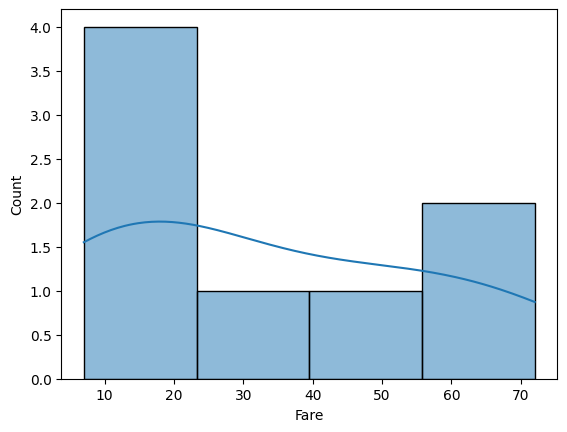

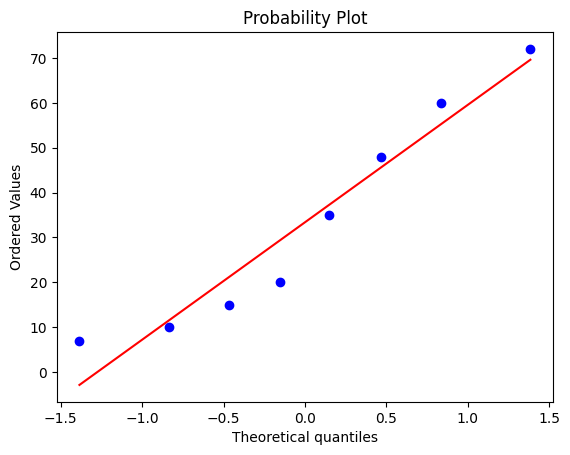

In [12]:
# Check distribution and skewness
# Positive skew = long right tail; negative skew = long left tail
print(X_train.skew())

sns.histplot(X_train["Fare"], kde=True)
plt.show()

# Q-Q plot: points near the line suggest approximate normality
from scipy import stats

stats.probplot(X_train["Fare"], dist="norm", plot=plt)
plt.show()


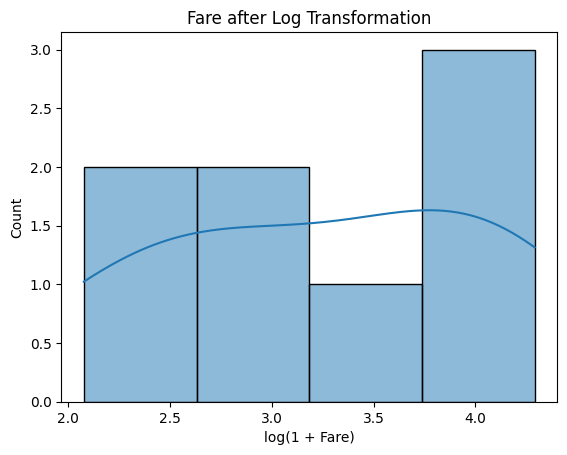

In [13]:

import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.preprocessing import FunctionTransformer

# log1p(x) = log(1 + x); reduces right skew for suitable data
log_transformer = FunctionTransformer(np.log1p)

X_train_log = log_transformer.fit_transform(X_train[["Fare"]])
X_test_log = log_transformer.transform(X_test[["Fare"]])

# Convert to 1D array for plotting
sns.histplot(x=np.asarray(X_train_log).ravel(), kde=True)
plt.title("Fare after Log Transformation")
plt.xlabel("log(1 + Fare)")
plt.show()


In [14]:
# PowerTransformer
from sklearn.preprocessing import PowerTransformer

# Box-Cox requires strictly positive values.
# Yeo-Johnson also supports zero and negative values.
# Both estimate lambda; standardization is enabled by default.

box_cox = PowerTransformer(method="box-cox")
yeo_johnson = PowerTransformer(method="yeo-johnson")

X_train_boxcox = box_cox.fit_transform(X_train[["Fare"]])
X_test_boxcox = box_cox.transform(X_test[["Fare"]])

X_train_yeo = yeo_johnson.fit_transform(X_train[["Fare"]])
X_test_yeo = yeo_johnson.transform(X_test[["Fare"]])

print("Box-Cox lambda:", box_cox.lambdas_)
print("Yeo-Johnson lambda:", yeo_johnson.lambdas_)


Box-Cox lambda: [0.17957827]
Yeo-Johnson lambda: [0.15825048]
